# qwen3-1.7b vs qwen3-4b: where does the model change its mind?

Same experiment, same prompts, same lenses method, both models in float32 computation:
relations author, capital, color, composer; 605 facts × 19 linguistic variants (11,495 prompts per model).
Only facts that the model knows (without the assertion it picks its memorised answer) and rows that end with the context or the prior answer.

The two models have different depth (1.7B: 28 layers, 4B: 36 layers), so layers are compared on a **relative depth** scale:
relative depth = layer / (number of layers − 1), 0 = first layer, 1 = last layer.
Colours: **violet = qwen3-1.7b**, **aqua = qwen3-4b**. Line style: **solid = context won**, **dashed = prior won**.


In [1]:
import json, numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from pathlib import Path
from textwrap import fill, wrap
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
%matplotlib inline

ROOT = Path.cwd()
while not (ROOT / 'results').is_dir():
    ROOT = ROOT.parent
OUT = ROOT / 'results/comparison'; OUT.mkdir(parents=True, exist_ok=True)
SUBSETS = {'qwen3-1.7b': 'results/qwen3-1.7b/qwen3-1.7b_4relations.parquet', 'qwen3-4b': 'results/qwen3-4b/qwen3-4b_4relations.parquet'}

MCOL = {'qwen3-1.7b': '#6250d6', 'qwen3-4b': '#1baf7a'}
CTX, PRI = '#2a78d6', '#e34948'
INK, INK2, MUTED, GRID, BASE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'font.size': 9, 'axes.titlesize': 10, 'legend.frameon': False, 'savefig.bbox': 'tight',
})
TERMS = ('Context answer = the answer stated in the assertion added to the prompt (it contradicts the fact). '
         'Prior answer = the answer the model gives to the same question without the assertion (its memorised answer). '
         '"Context won" / "prior won" = which of the two the model gives as its final output. Only facts the model knows are used.')
DELTA_T = ('δ = logit(first token of the context answer) − logit(first token of the prior answer) at one layer. '
           'Shift of δ = δ with the assertion − δ without it: how far the assertion pushes the layer toward the context answer.')
LENS_T = ('Logit lens: layer output → final norm → output matrix, as if the model stopped there. '
          'J-lens: the layer output is first multiplied by the Jacobian lens matrix of that layer (neuronpedia/jacobian-lens, fitted on wikitext), then decoded the same way. '
          'The J-lens has no matrix for the last layer.')
REL_T = 'Relative depth = layer / (number of layers − 1): qwen3-1.7b has 28 layers (0-27), qwen3-4b has 36 (0-35).'

def caption(fig, *parts, y=-0.01):
    width = int(fig.get_size_inches()[0] * 15)
    fig.text(0.01, y, '\n'.join(fill(t, width) for t in parts), ha='left', va='top', fontsize=8.5, color=INK2, linespacing=1.4)

DIM_ORDER = ['evidentiality', 'epistemic_stance', 'form', 'tone']
D = {}
for m, path in SUBSETS.items():
    raw = pd.read_parquet(ROOT / path)
    df = raw[raw.knows_prior & raw.choice.isin(['context', 'prior'])].copy().reset_index(drop=True)
    for c in ['delta_logit_lens', 'delta_jlens', 'delta0_logit_lens', 'delta0_jlens', 'jlens_layers']:
        df[c] = df[c].map(json.loads)
    LL, JL = np.stack(df.delta_logit_lens), np.stack(df.delta_jlens)
    LL0, JL0 = np.stack(df.delta0_logit_lens), np.stack(df.delta0_jlens)
    nl = LL.shape[1]
    x_ll = np.arange(nl); x_jl = np.array(df.jlens_layers.iloc[0])
    is_ctx = (df.choice == 'context').values
    gap = LL[is_ctx].mean(0) - LL[~is_ctx].mean(0)
    sep = int(np.where(gap > 2)[0][0])
    D[m] = dict(raw=raw, df=df, LL=LL, JL=JL, S_LL=LL - LL0, S_JL=JL - JL0, nl=nl, x_ll=x_ll, x_jl=x_jl,
                r_ll=x_ll / (nl - 1), r_jl=x_jl / (nl - 1), is_ctx=is_ctx, sep=sep)
    known = raw.drop_duplicates('fact_index').knows_prior.mean()
    print(f'{m}: layers {nl} | facts {raw.fact_index.nunique()} | known facts {known:.1%} | rows used {len(df):,} '
          f'(context won {is_ctx.sum():,} = {is_ctx.mean():.1%}) | curves split (>2 logits) at layer {sep} = depth {sep/(nl-1):.2f}')
CATS = (D['qwen3-1.7b']['df'][['dimension', 'category']].drop_duplicates()
        .assign(d=lambda t: t.dimension.map(DIM_ORDER.index)).sort_values(['d', 'category'])[['dimension', 'category']])
CATS = list(CATS.itertuples(index=False, name=None))


qwen3-1.7b: layers 28 | facts 605 | known facts 58.8% | rows used 6,710 (context won 4,472 = 66.6%) | curves split (>2 logits) at layer 19 = depth 0.70


qwen3-4b: layers 36 | facts 605 | known facts 65.6% | rows used 7,503 (context won 4,730 = 63.0%) | curves split (>2 logits) at layer 24 = depth 0.69


## C1. Behaviour: how often the context wins, per linguistic type, in each model

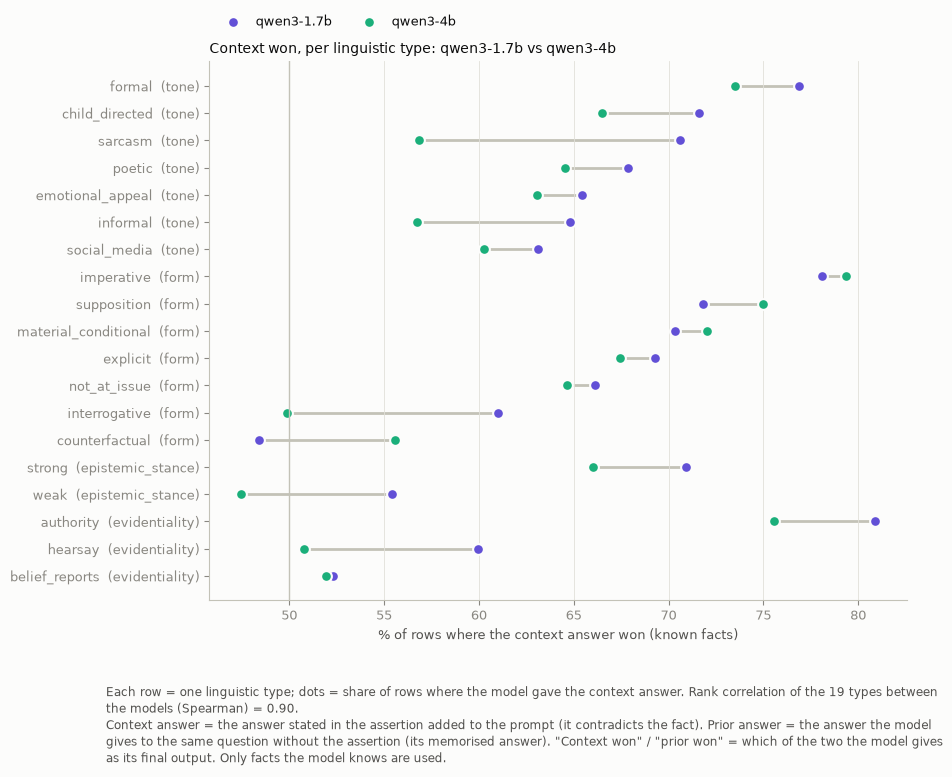

Spearman rho of type ranking between models: 0.904


,dimension,category,qwen3-1.7b n,qwen3-1.7b ctx,qwen3-4b n,qwen3-4b ctx
0,evidentiality,belief_reports,344,52.3,391,51.9
1,evidentiality,hearsay,352,59.9,394,50.8
2,evidentiality,authority,356,80.9,397,75.6
3,epistemic_stance,weak,352,55.4,394,47.5
4,epistemic_stance,strong,354,70.9,397,66.0
5,form,counterfactual,341,48.4,394,55.6
6,form,interrogative,354,61.0,389,49.9
7,form,not_at_issue,354,66.1,396,64.6
8,form,explicit,355,69.3,396,67.4
9,form,material_conditional,354,70.3,397,72.0


In [2]:
beh = []
for m in D:
    df = D[m]['df']
    g = df.groupby(['dimension', 'category']).choice.agg(n='size', ctx=lambda s: (s == 'context').mean() * 100)
    beh.append(g.add_prefix(m + ' '))
beh = pd.concat(beh, axis=1).reset_index()
beh['dim_i'] = beh.dimension.map(DIM_ORDER.index)
beh = beh.sort_values(['dim_i', 'qwen3-1.7b ctx']).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(beh))
for i, r in beh.iterrows():
    ax.plot([r['qwen3-1.7b ctx'], r['qwen3-4b ctx']], [i, i], color=BASE, lw=2, zorder=1)
for m in D:
    ax.scatter(beh[m + ' ctx'], y, s=60, color=MCOL[m], zorder=2, label=m, edgecolor='#fcfcfb', linewidth=1.5)
ax.set_yticks(y, [f'{r.category}  ({r.dimension})' for r in beh.itertuples()])
ax.axvline(50, color=BASE, lw=1); ax.set_xlabel('% of rows where the context answer won (known facts)')
ax.grid(axis='y', visible=False)
ax.set_title('Context won, per linguistic type: qwen3-1.7b vs qwen3-4b', loc='left')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.04), ncol=2)
rho = beh['qwen3-1.7b ctx'].rank().corr(beh['qwen3-4b ctx'].rank())  # Spearman = Pearson on ranks
caption(fig, f'Each row = one linguistic type; dots = share of rows where the model gave the context answer. Rank correlation of the 19 types between the models (Spearman) = {rho:.2f}.', TERMS)
fig.savefig(OUT / 'cmp1_behaviour.png', dpi=150); FIGC1 = fig; plt.show()
print('Spearman rho of type ranking between models:', round(rho, 3))
beh.drop(columns='dim_i').round(1)


## C2. Lens curves of both models on one relative-depth axis

Mean shift of δ caused by the assertion, pooled over all 19 types. Left: logit lens; right: J-lens.

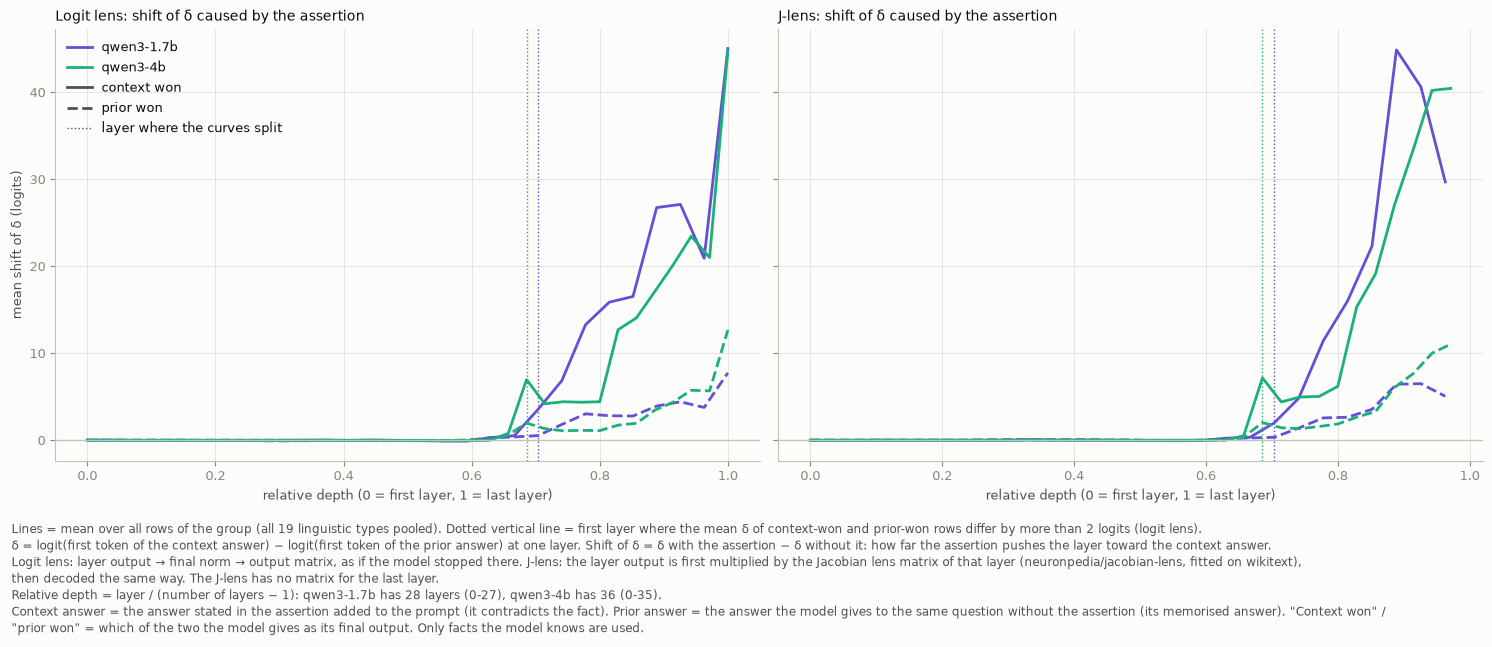

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, key, xk, ttl in [(axes[0], 'S_LL', 'r_ll', 'Logit lens'), (axes[1], 'S_JL', 'r_jl', 'J-lens')]:
    for m in D:
        d = D[m]
        ax.plot(d[xk], d[key][d['is_ctx']].mean(0), color=MCOL[m], lw=2)
        ax.plot(d[xk], d[key][~d['is_ctx']].mean(0), color=MCOL[m], lw=2, ls='--')
        ax.axvline(d['sep'] / (d['nl'] - 1), color=MCOL[m], lw=1, ls=':')
    ax.axhline(0, color=BASE, lw=1)
    ax.set_title(f'{ttl}: shift of δ caused by the assertion', loc='left'); ax.set_xlabel('relative depth (0 = first layer, 1 = last layer)')
axes[0].set_ylabel('mean shift of δ (logits)')
h = [Line2D([], [], color=MCOL[m], lw=2, label=m) for m in D] + \
    [Line2D([], [], color=INK2, lw=2, label='context won'), Line2D([], [], color=INK2, lw=2, ls='--', label='prior won'),
     Line2D([], [], color=INK2, lw=1, ls=':', label='layer where the curves split')]
axes[0].legend(handles=h, loc='upper left')
fig.tight_layout()
caption(fig, 'Lines = mean over all rows of the group (all 19 linguistic types pooled). Dotted vertical line = first layer where the mean δ of context-won and prior-won rows differ by more than 2 logits (logit lens).',
        DELTA_T, LENS_T, REL_T, TERMS)
fig.savefig(OUT / 'cmp2_shift_relative_depth.png', dpi=150); FIGC2 = fig; plt.show()


## C3. The same curves in absolute layers, and raw δ

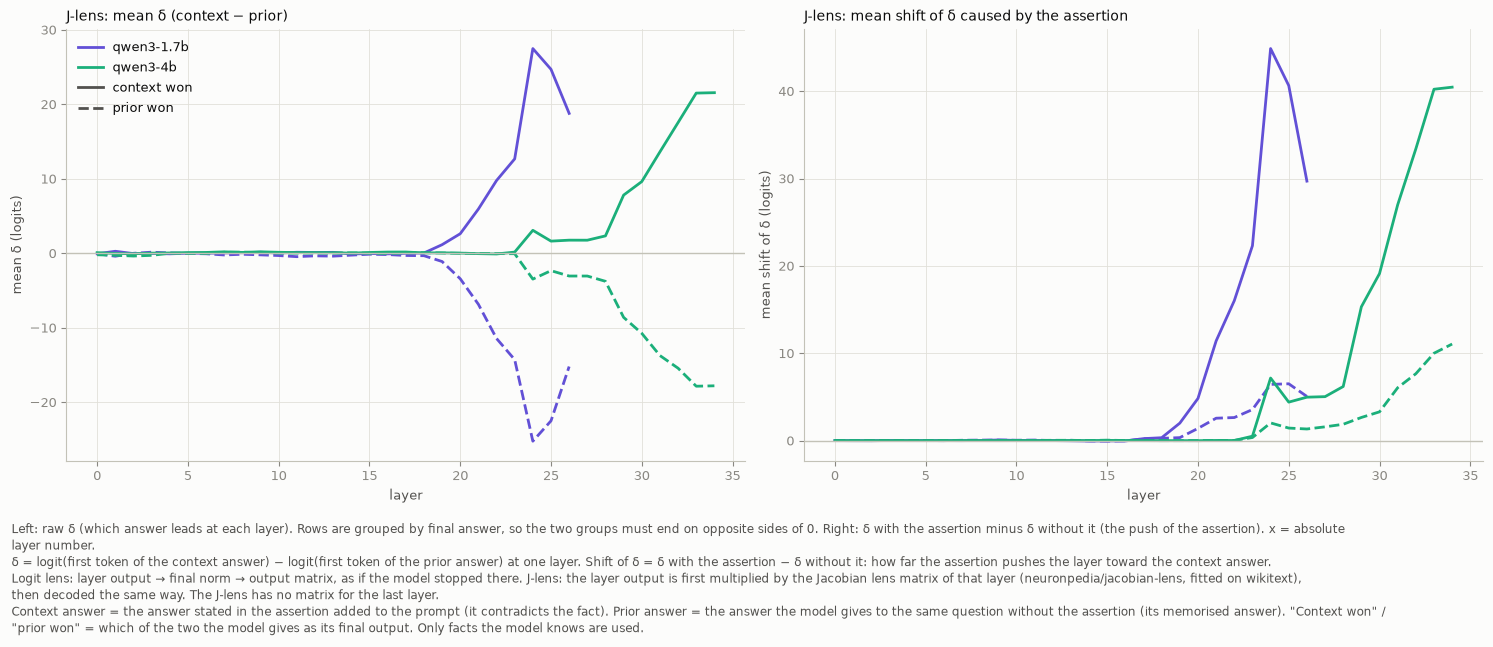

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, key, ttl, yl in [(axes[0], 'JL', 'J-lens: mean δ (context − prior)', 'mean δ (logits)'),
                         (axes[1], 'S_JL', 'J-lens: mean shift of δ caused by the assertion', 'mean shift of δ (logits)')]:
    for m in D:
        d = D[m]
        ax.plot(d['x_jl'], d[key][d['is_ctx']].mean(0), color=MCOL[m], lw=2)
        ax.plot(d['x_jl'], d[key][~d['is_ctx']].mean(0), color=MCOL[m], lw=2, ls='--')
    ax.axhline(0, color=BASE, lw=1); ax.set_title(ttl, loc='left'); ax.set_xlabel('layer'); ax.set_ylabel(yl)
h = [Line2D([], [], color=MCOL[m], lw=2, label=m) for m in D] + \
    [Line2D([], [], color=INK2, lw=2, label='context won'), Line2D([], [], color=INK2, lw=2, ls='--', label='prior won')]
axes[0].legend(handles=h, loc='upper left')
fig.tight_layout()
caption(fig, 'Left: raw δ (which answer leads at each layer). Rows are grouped by final answer, so the two groups must end on opposite sides of 0. '
        'Right: δ with the assertion minus δ without it (the push of the assertion). x = absolute layer number.', DELTA_T, LENS_T, TERMS)
fig.savefig(OUT / 'cmp3_jlens_absolute_layers.png', dpi=150); FIGC3 = fig; plt.show()


## C4. Key layers per linguistic type, on relative depth

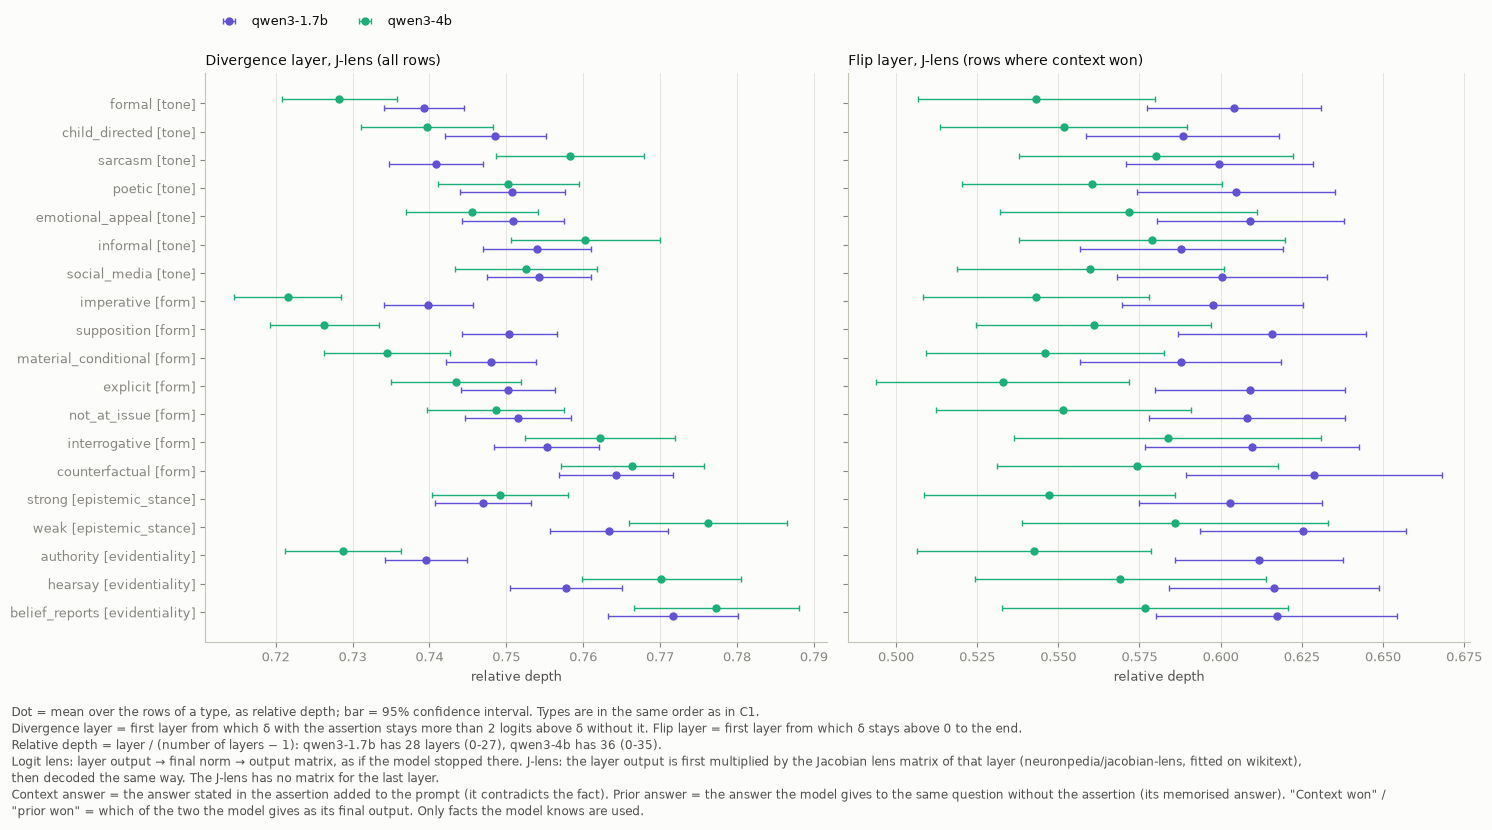

In [5]:
def mean_ci(v):
    v = v.dropna(); return v.mean(), (1.96 * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0)

metrics = [('Divergence layer, J-lens (all rows)', 'divergence_jl', None),
           ('Flip layer, J-lens (rows where context won)', 'flip_jlens', True)]
order = list(beh[['dimension', 'category']].itertuples(index=False, name=None))
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
y = np.arange(len(order))
KEY = []
for ax, (ttl, col, won) in zip(axes, metrics):
    for k, m in enumerate(D):
        d = D[m]; df = d['df']
        for i, (dim, cat) in enumerate(order):
            msk = (df.dimension == dim) & (df.category == cat)
            if won is not None: msk &= (df.choice == 'context') == won
            mu, ci = mean_ci(df.loc[msk, col] / (d['nl'] - 1))
            ax.errorbar(mu, i + (k - 0.5) * 0.3, xerr=ci, fmt='o', ms=5, color=MCOL[m], ecolor=MCOL[m], elinewidth=1, capsize=2,
                        label=m if i == 0 else None)
            KEY.append(dict(model=m, metric=col, dimension=dim, category=cat, rel=mu, layer=mu * (d['nl'] - 1)))
    ax.set_title(ttl, loc='left'); ax.set_xlabel('relative depth'); ax.grid(axis='y', visible=False)
axes[0].set_yticks(y, [f'{c} [{d}]' for d, c in order]); axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1.06), ncol=2)
fig.tight_layout()
caption(fig, 'Dot = mean over the rows of a type, as relative depth; bar = 95% confidence interval. Types are in the same order as in C1.',
        'Divergence layer = first layer from which δ with the assertion stays more than 2 logits above δ without it. Flip layer = first layer from which δ stays above 0 to the end.',
        REL_T, LENS_T, TERMS)
fig.savefig(OUT / 'cmp4_key_layers_relative.png', dpi=150); FIGC4 = fig; plt.show()
KEY = pd.DataFrame(KEY)


## C5. Do the same types win in both models?

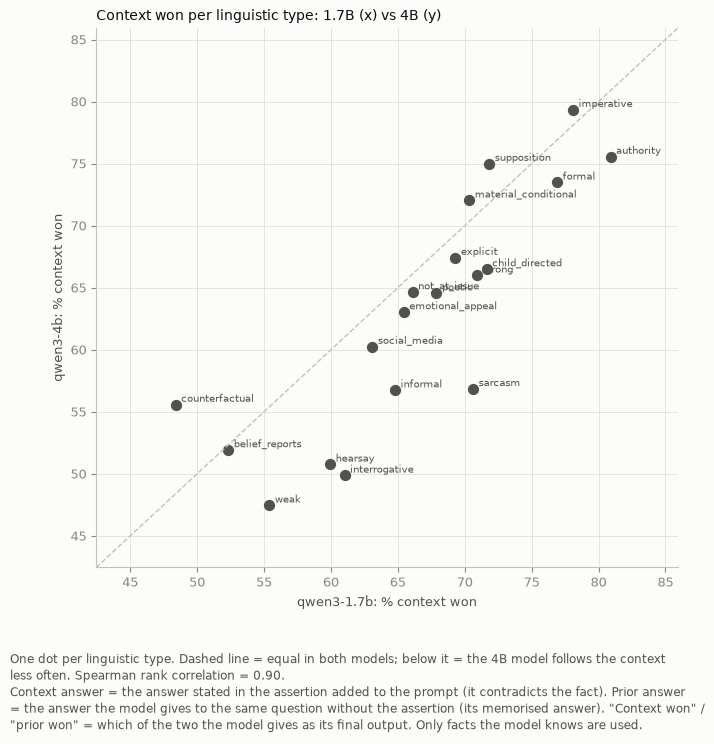

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(beh['qwen3-1.7b ctx'], beh['qwen3-4b ctx'], s=50, color=INK2, zorder=2)
for _, r in beh.iterrows():
    ax.annotate(r['category'], (r['qwen3-1.7b ctx'], r['qwen3-4b ctx']), fontsize=7.5, color=INK2, xytext=(4, 2), textcoords='offset points')
lo = min(beh['qwen3-1.7b ctx'].min(), beh['qwen3-4b ctx'].min()) - 5; hi = max(beh['qwen3-1.7b ctx'].max(), beh['qwen3-4b ctx'].max()) + 5
ax.plot([lo, hi], [lo, hi], color=BASE, lw=1, ls='--'); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel('qwen3-1.7b: % context won'); ax.set_ylabel('qwen3-4b: % context won')
ax.set_title('Context won per linguistic type: 1.7B (x) vs 4B (y)', loc='left')
caption(fig, f'One dot per linguistic type. Dashed line = equal in both models; below it = the 4B model follows the context less often. Spearman rank correlation = {rho:.2f}.', TERMS)
fig.savefig(OUT / 'cmp5_types_scatter.png', dpi=150); FIGC5 = fig; plt.show()


## C6. Summary table

In [7]:
rows = []
for dim, cat in order:
    r = {'dimension': dim, 'category': cat}
    for m in D:
        d = D[m]; df = d['df']; msk = ((df.dimension == dim) & (df.category == cat)).values
        r[f'{m} n'] = int(msk.sum())
        r[f'{m} ctx %'] = 100 * d['is_ctx'][msk].mean()
        r[f'{m} div JL (layer)'] = df.loc[msk, 'divergence_jl'].mean()
        r[f'{m} div JL (rel)'] = df.loc[msk, 'divergence_jl'].mean() / (d['nl'] - 1)
        pk = int(np.argmax(d['S_JL'][d['is_ctx']].mean(0)))
        r[f'{m} max shift JL (ctx)'] = d['S_JL'][msk & d['is_ctx'], pk].mean()
    rows.append(r)
TAB = pd.DataFrame(rows).round(2)
TAB.to_csv(OUT / 'comparison_by_category.csv', index=False)
for m in D:
    d = D[m]; pk = int(np.argmax(d['S_JL'][d['is_ctx']].mean(0)))
    print(f"{m}: J-lens shift peaks at layer {d['x_jl'][pk]} (depth {d['x_jl'][pk]/(d['nl']-1):.2f}); "
          f"context-won {d['S_JL'][d['is_ctx'], pk].mean():.1f}, prior-won {d['S_JL'][~d['is_ctx'], pk].mean():.1f} logits; "
          f"split at layer {d['sep']} (depth {d['sep']/(d['nl']-1):.2f}); "
          f"median divergence JL {d['df'].divergence_jl.median()} (depth {d['df'].divergence_jl.median()/(d['nl']-1):.2f}); "
          f"median flip JL (ctx) {d['df'].loc[d['is_ctx'], 'flip_jlens'].median()}")
    early = d['sep'] - 1
    print(f"   mean |shift| before layer {early}: LL {np.abs(d['S_LL'][:, :early].mean(0)).max():.2f}, JL {np.abs(d['S_JL'][:, :early].mean(0)).max():.2f}")
    tt = TAB.set_index('category')[f'{m} ctx %']
    print('   corr(ctx %, divergence layer) across types:', round(tt.corr(TAB.set_index('category')[f'{m} div JL (layer)']), 2),
          '| corr(ctx %, max shift):', round(tt.corr(TAB.set_index('category')[f'{m} max shift JL (ctx)']), 2))
TAB


qwen3-1.7b: J-lens shift peaks at layer 24 (depth 0.89); context-won 44.9, prior-won 6.4 logits; split at layer 19 (depth 0.70); median divergence JL 20.0 (depth 0.74); median flip JL (ctx) 19.0
   mean |shift| before layer 18: LL 0.31, JL 0.23
   corr(ctx %, divergence layer) across types: -0.94 | corr(ctx %, max shift): 0.97
qwen3-4b: J-lens shift peaks at layer 34 (depth 0.97); context-won 40.5, prior-won 11.1 logits; split at layer 24 (depth 0.69); median divergence JL 24.0 (depth 0.69); median flip JL (ctx) 24.0
   mean |shift| before layer 23: LL 0.05, JL 0.04
   corr(ctx %, divergence layer) across types: -0.97 | corr(ctx %, max shift): 0.94


,dimension,category,qwen3-1.7b n,qwen3-1.7b ctx %,qwen3-1.7b div JL (layer),qwen3-1.7b div JL (rel),qwen3-1.7b max shift JL (ctx),qwen3-4b n,qwen3-4b ctx %,qwen3-4b div JL (layer),qwen3-4b div JL (rel),qwen3-4b max shift JL (ctx)
0,evidentiality,belief_reports,344,52.33,20.83,0.77,40.65,391,51.92,27.21,0.78,36.39
1,evidentiality,hearsay,352,59.94,20.46,0.76,42.79,394,50.76,26.96,0.77,35.76
2,evidentiality,authority,356,80.90,19.97,0.74,47.78,397,75.57,25.51,0.73,44.42
3,epistemic_stance,weak,352,55.40,20.61,0.76,40.99,394,47.46,27.17,0.78,33.88
4,epistemic_stance,strong,354,70.90,20.17,0.75,46.32,397,65.99,26.22,0.75,42.10
5,form,counterfactual,341,48.39,20.63,0.76,40.03,394,55.58,26.82,0.77,36.42
6,form,interrogative,354,61.02,20.39,0.76,42.79,389,49.87,26.68,0.76,33.28
7,form,not_at_issue,354,66.10,20.29,0.75,44.59,396,64.65,26.20,0.75,41.74
8,form,explicit,355,69.30,20.26,0.75,45.42,396,67.42,26.02,0.74,41.96
9,form,material_conditional,354,70.34,20.20,0.75,45.08,397,72.04,25.71,0.73,42.52


## Findings

- **Same data, two sizes:** both models saw the same 605 facts × 19 variants. The 4B model knows more of the facts (65.6% vs 58.8% of rows have a known prior). It follows the context slightly less often (63.0% vs 66.6% of known-fact rows).
- **The turn sits at the same relative depth.** The context-won and prior-won curves split at layer 19 of 28 in 1.7B (depth 0.70) and at layer 24 of 36 in 4B (depth 0.69). In both models nothing readable happens before that point (mean |shift| below 0.3 logits). The turn is narrow, about 3 layers. The larger model has more layers in total, but its decision point does not move earlier or later in relative terms.
- **The decision builds up differently after the turn.**
  - In 1.7B the J-lens shift rises smoothly and peaks at depth 0.89 (layer 24, 45 logits), then falls back at the last layers.
  - In 4B there is a first jump at the turn (7 logits at layer 24) and a plateau at layers 25–28. A second, larger rise follows from depth 0.8, reaching its peak at depth 0.97 (layer 34, 40 logits).
  - So in 4B a larger share of the decision is made in the very last layers.
- **Prior-won rows are pushed harder in 4B.** At the peak, the assertion moves δ by 11.1 logits in 4B against 6.4 in 1.7B. The bigger model "hears" the assertion as strongly but still keeps its memorised answer more often.
- **The same types persuade both models.** The ranking of the 19 types by context-won share is highly similar (Spearman ρ = 0.90). Authority, imperative, formal and supposition are on top in both models; belief_reports and weak stance are near the bottom in both.
- **Where the models differ by type:**
  - Several types lose much more of their effect in 4B: sarcasm (70.6% → 56.9%), interrogative (61.0% → 49.9%), hearsay (59.9% → 50.8%), informal (64.8% → 56.7%) and weak stance (55.4% → 47.5%).
  - Counterfactual is the only type that gains a lot (48.4% → 55.6%). Supposition and material_conditional gain a little (+2–3 points).
  - The larger model is more sensitive to how reliable the assertion sounds.
- **Layer timing follows behaviour in both models.** Types that win more often diverge earlier and push harder. The correlation of context-won share with the divergence layer is −0.94 in 1.7B and −0.97 in 4B; with the maximum J-lens shift it is +0.97 and +0.94. In relative depth the per-type divergence layers sit in the same narrow band in both models (0.72–0.78).
- **Caveats:**
  - Only 4 of 15 relations are used, and there are only two model sizes.
  - δ uses the first answer token only.
  - The J-lens matrices for the two models were fitted separately (on wikitext), so their absolute sizes are not strictly comparable. Layers and relative depth are the safer comparison.


In [8]:
REPORT_TEXT = ['Same data, two sizes: both models saw the same 605 facts × 19 variants. The 4B model knows more of the facts (65.6% vs 58.8% of rows have a known prior). It follows the context slightly less often (63.0% vs 66.6% of known-fact rows).', 'The turn sits at the same relative depth. The context-won and prior-won curves split at layer 19 of 28 in 1.7B (depth 0.70) and at layer 24 of 36 in 4B (depth 0.69). In both models nothing readable happens before that point (mean |shift| below 0.3 logits). The turn is narrow, about 3 layers. The larger model has more layers in total, but its decision point does not move earlier or later in relative terms.', 'The decision builds up differently after the turn.', 'In 1.7B the J-lens shift rises smoothly and peaks at depth 0.89 (layer 24, 45 logits), then falls back at the last layers.', 'In 4B there is a first jump at the turn (7 logits at layer 24) and a plateau at layers 25–28. A second, larger rise follows from depth 0.8, reaching its peak at depth 0.97 (layer 34, 40 logits).', 'So in 4B a larger share of the decision is made in the very last layers.', 'Prior-won rows are pushed harder in 4B. At the peak, the assertion moves δ by 11.1 logits in 4B against 6.4 in 1.7B. The bigger model "hears" the assertion as strongly but still keeps its memorised answer more often.', 'The same types persuade both models. The ranking of the 19 types by context-won share is highly similar (Spearman ρ = 0.90). Authority, imperative, formal and supposition are on top in both models; belief_reports and weak stance are near the bottom in both.', 'Where the models differ by type:', 'Several types lose much more of their effect in 4B: sarcasm (70.6% → 56.9%), interrogative (61.0% → 49.9%), hearsay (59.9% → 50.8%), informal (64.8% → 56.7%) and weak stance (55.4% → 47.5%).', 'Counterfactual is the only type that gains a lot (48.4% → 55.6%). Supposition and material_conditional gain a little (+2–3 points).', 'The larger model is more sensitive to how reliable the assertion sounds.', 'Layer timing follows behaviour in both models. Types that win more often diverge earlier and push harder. The correlation of context-won share with the divergence layer is −0.94 in 1.7B and −0.97 in 4B; with the maximum J-lens shift it is +0.97 and +0.94. In relative depth the per-type divergence layers sit in the same narrow band in both models (0.72–0.78).', 'Caveats:', 'Only 4 of 15 relations are used, and there are only two model sizes.', 'δ uses the first answer token only.', 'The J-lens matrices for the two models were fitted separately (on wikitext), so their absolute sizes are not strictly comparable. Layers and relative depth are the safer comparison.']
def text_page(pdf, title, paragraphs):
    fig = plt.figure(figsize=(8.27, 11.69)); fig.text(0.07, 0.95, title, fontsize=15, weight='bold', va='top')
    yy = 0.91
    for p in paragraphs:
        for line in wrap(p, 95) or ['']:
            fig.text(0.07, yy, line, fontsize=9.5, va='top'); yy -= 0.018
        yy -= 0.012
    pdf.savefig(fig); plt.close(fig)

PDF = OUT / 'qwen3-1.7b_vs_4b_report.pdf'
with PdfPages(PDF) as pdf:
    text_page(pdf, 'qwen3-1.7b vs qwen3-4b: where the model changes its mind', REPORT_TEXT)
    for f in [FIGC1, FIGC2, FIGC3, FIGC4, FIGC5]:
        pdf.savefig(f, bbox_inches='tight')
    show = TAB[['dimension', 'category'] + [c for c in TAB.columns if ('ctx %' in c or 'rel' in c or 'max shift' in c)]]
    fig, ax = plt.subplots(figsize=(16, 7)); ax.axis('off')
    t = ax.table(cellText=show.values, colLabels=['\n'.join(wrap(c, 14)) for c in show.columns], loc='center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(7.5); t.scale(1, 1.5)
    for (r, c), cell in t.get_celld().items():
        if r == 0: cell.set_height(cell.get_height() * 2.2)
    ax.set_title('Per linguistic type: % context won, divergence layer (relative depth), largest J-lens shift (logits, context-won rows)', loc='left')
    pdf.savefig(fig, bbox_inches='tight'); plt.close(fig)
print('saved', PDF.relative_to(ROOT))


saved results/comparison/qwen3-1.7b_vs_4b_report.pdf
